# Labelling 100 Objaverse objects, then teaching Qwen the choice

Zero-shot, Qwen3-VL-2B answers the same gripper for every object — `2-finger` for all ten in
`pipeline_finray_qwen.ipynb`, `robotiq_2f_140` for all ten in `pipeline_objaverse.ipynb`. It is
not deciding anything. This notebook asks whether a small labelled set fixes that.

**Read the labels for what they are.** There is no ground truth for 2-finger versus 4-finger on
Objaverse — no simulator we can run here, no physical trials on 100 artist meshes. So the labels
are *mine*. To keep them auditable rather than arbitrary, each one comes from a single measured
geometric criterion, stated below, and the reasoning string is generated from that measurement.
Training on them distils a rule into the model; it does not teach it the truth. **The ceiling is
the rule's own quality.**

## 1. Setup

In [1]:
import json, pathlib, subprocess, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt

ROOT = pathlib.Path.cwd()
OUT  = ROOT/"stage1_gripper"/"results"/"labels"
sys.path.insert(0, str(ROOT/"stage1_gripper"/"scripts"))
from label_geometry import features, label, APERTURE_MM

labels = json.loads((OUT/"labels_100.json").read_text())
print(f"{len(labels)} objects annotated")
print(pd.Series([v["gripper"] for v in labels.values()]).value_counts().to_string())

100 objects annotated
2-finger    81
4-finger    19


## 2. The labelling rule

The Objaverse assets are **not watertight**, so face normals cannot be trusted and any
force-closure or antipodal test built on them returns noise. Everything is therefore computed from
surface point positions only.

The criterion is one number: **how circular is the cross-section across the object's long axis?**
A 2-finger fin-ray grip needs two opposing flats to pinch against. Round cross-sections have none
— the object rolls out of a two-point pinch — and that is exactly what the second pair of fingers
is for. A circle scores 1.0, a square 0.71, a flat slab near 0. The threshold is **0.70**, just
below a square.

### The version of this rule I threw away

The first rule had a second branch: *also* choose 4-finger when the object is "bulky in every
direction", from bounding-box ratios. The numbers looked reasonable. Then I rendered all 25 objects
it had labelled 4-finger and looked at them — and that branch had flagged a **table top**
(circularity 0.14), a **telephone** (0.26), a **dumpster** and a **cat stand**. Flat panels and
boxes, which have the best pinching faces of anything in the set.

Bounding-box ratios mislead on hollow or sparse meshes: a table is a thin plate on thin legs, so
its box is nearly cubic while its surface is almost all flat. The branch is gone. This is the one
thing in the notebook that needed eyes on the data rather than a metric.

In [2]:
print(label.__doc__)

Documented rule. Returns (gripper, reason).

    One criterion, measured from the surface: how circular is the cross-section
    across the object's long axis? A 2-finger fin-ray grip needs two opposing
    flats to pinch against. Round cross-sections have none -- the object rolls
    out of a two-point pinch -- and that is what the extra pair of fingers is
    for. A square cross-section scores 0.71, a circle 1.0, a flat slab near 0.

    An earlier version of this rule had a second "bulky in every direction"
    branch based on bounding-box ratios. Looking at the labels it produced
    showed it firing on flat panels and boxes (a table top scoring 0.14, a
    telephone 0.26) -- shapes with perfectly good faces to pinch. Bounding-box
    ratios mislead on hollow or sparse meshes, so that branch is gone.
    


### What the rule chose

All 19 objects labelled 4-finger, drawn from their meshes:

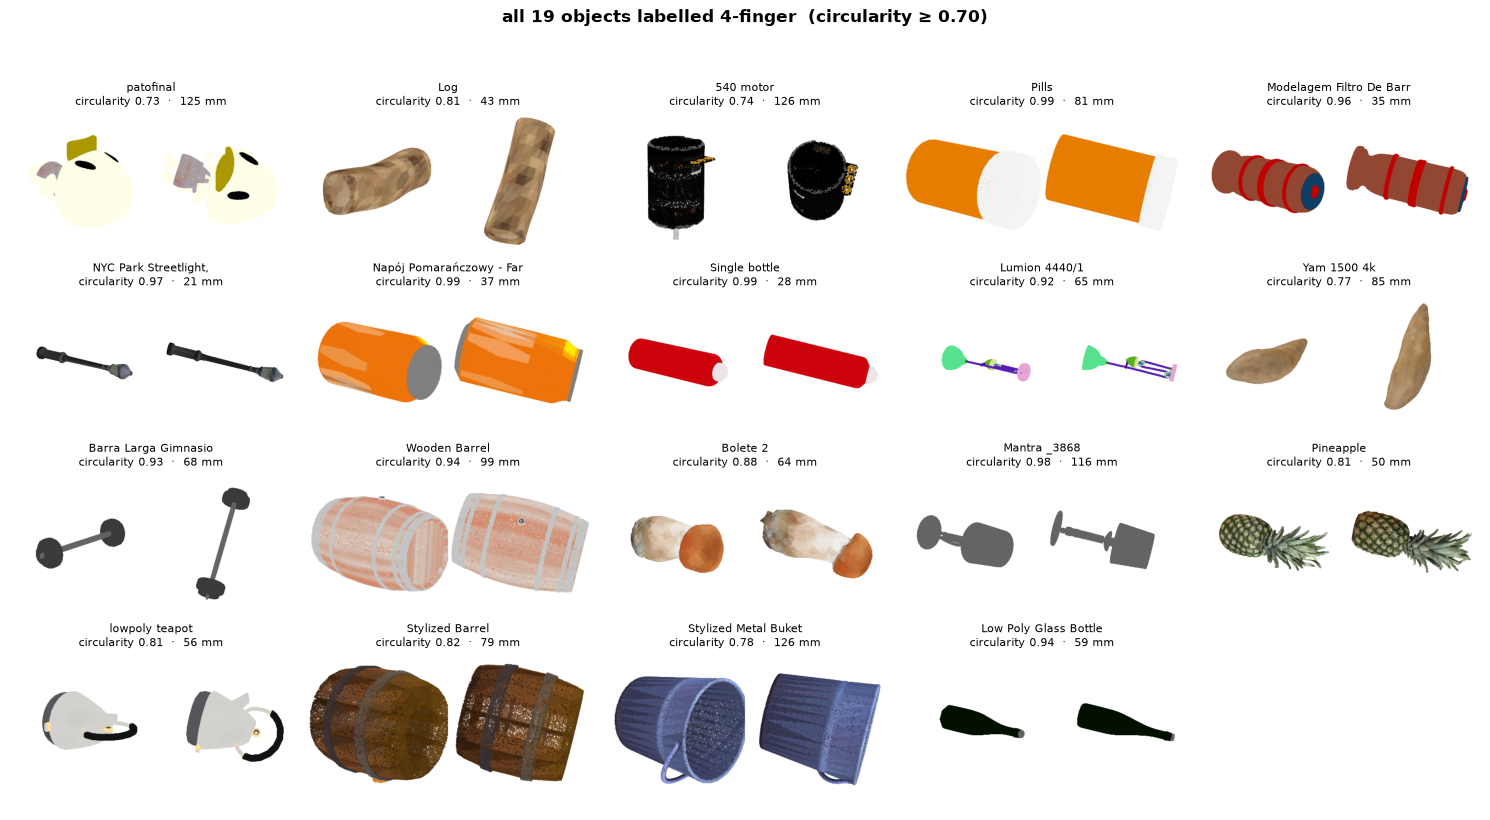

In [3]:
four = [(u, v) for u, v in labels.items() if v["gripper"] == "4-finger"]
cols = 5; rows = (len(four)+cols-1)//cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 2.05*rows))
for ax, (u, v) in zip(axes.ravel(), four):
    ax.imshow(plt.imread(OUT/"renders"/f"{u[:8]}.png")); ax.axis("off")
    ax.set_title(f"{v['name'][:24]}\ncircularity {v['circularity']:.2f}  ·  "
                 f"{v['short_mm']:.0f} mm", fontsize=8)
for ax in axes.ravel()[len(four):]: ax.axis("off")
fig.suptitle(f"all {len(four)} objects labelled 4-finger  (circularity ≥ 0.70)",
             fontweight="bold", y=.995)
fig.tight_layout(rect=(0, 0, 1, .96))
fig.savefig(OUT/"labels_4finger.png", dpi=140, facecolor="white")
plt.show()

## 3. The split

The natural rate is about **one round object in five** — Objaverse is mostly vehicles, figures and
props, which are elongated or irregular. A 50/50 set is not available without bending the labels,
so instead:

- **train is balanced** (13 + 13). Training at the natural rate would teach the class prior, which
  is the failure we are trying to fix.
- **test keeps the natural rate** (3 four-finger against 65 two-finger), so the evaluation is not
  flattered. With that imbalance, accuracy alone is useless — a model answering `2-finger` every
  time scores 96%. Per-class recall is the number to read.

In [4]:
for name in ["train", "valid", "test"]:
    rows = [json.loads(l) for l in open(OUT/"vlm_data"/f"{name}.jsonl")]
    n4 = sum(r["gripper"] == "4-finger" for r in rows)
    print(f"{name:6s} {len(rows):3d} examples   {n4:2d} 4-finger / {len(rows)-n4:2d} 2-finger")

example = json.loads(open(OUT/"vlm_data"/"train.jsonl").readline())
print("\n--- one training example ---")
print(example["messages"][0]["content"][:300], "...")
print("\nanswer:", repr(example["messages"][1]["content"]))

train   26 examples   13 4-finger / 13 2-finger
valid    6 examples    3 4-finger /  3 2-finger
test    68 examples    3 4-finger / 65 2-finger

--- one training example ---
This object is called "Army_Soldier_75". The image shows two views of its 3D mesh.
It measures 110 mm across its shortest axis and 151 mm across its longest.

A robot must pick it up with one of two fin-ray grippers. The fingers are identical -- only how many close on the object differs:
  2-finger  ...

answer: 'gripper: 2-finger\nreason: the cross-section has flats to pinch against (circularity 0.27) across a 110 mm narrow direction'


## 4. Before training

Same prompt, same images, no adapter.

In [5]:
zs = json.loads((OUT/"eval_zeroshot.json").read_text())

def report(tag, r):
    print(f"{tag:12s} accuracy {r['accuracy']:.1%}   "
          + "   ".join(f"{c} recall {v['recall']:.0%} (n={v['n']})"
                       for c, v in r["by_class"].items()))
    print(f"{'':12s} predicted {dict(r['predicted'])}")

report("zero-shot", zs)

zero-shot    accuracy 94.1%   2-finger recall 98% (n=65)   4-finger recall 0% (n=3)
             predicted {'2-finger': 67, '4-finger': 1}


## 5. Fine-tune

LoRA on the 26 balanced training examples, the same recipe as stages 2 and 3:

```
python -m mlx_vlm.lora --model-path mlx-community/Qwen3-VL-2B-Instruct-4bit \
  --dataset vlm_data --epochs 8 --batch-size 1 --learning-rate 1e-4 \
  --lora-rank 8 --lora-alpha 16 --lora-dropout 0.05 \
  --grad-checkpoint --max-seq-length 2048 --output-path adapters
```

8.7 M trainable parameters (0.41% of the model), 4.2 GB peak, 208 iterations.

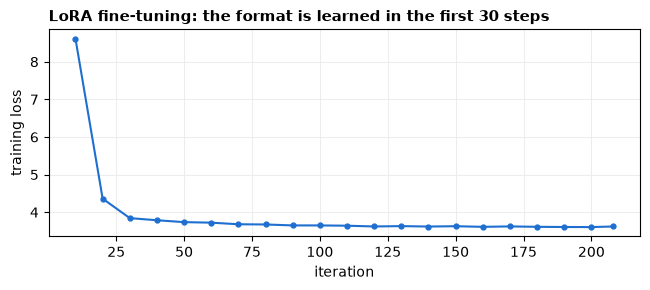

loss 8.61 at iter 10 -> 3.62 at iter 208


In [6]:
import re

rows = [re.search(r"Iter (\d+): Train loss ([0-9.]+)", l)
        for l in open(OUT/"lora_training.log")]
curve = [(int(m.group(1)), float(m.group(2))) for m in rows if m]

it, loss = zip(*curve)
fig, ax = plt.subplots(figsize=(6.6, 3))
ax.plot(it, loss, marker="o", ms=3.5, color="#1f6fd0")
ax.set_xlabel("iteration"); ax.set_ylabel("training loss")
ax.set_title("LoRA fine-tuning: the format is learned in the first 30 steps",
             loc="left", fontweight="bold", fontsize=10.5)
ax.grid(color=".93"); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(OUT/"lora_loss.png", dpi=150, facecolor="white")
plt.show()

print(f"loss {loss[0]:.2f} at iter {it[0]} -> {loss[-1]:.2f} at iter {it[-1]}")

## 6. After training

In [7]:
ft = json.loads((OUT/"eval_finetuned.json").read_text())
report("zero-shot", zs)
report("fine-tuned", ft)

cmp = pd.DataFrame([
    dict(model="zero-shot",  accuracy=zs["accuracy"],
         recall_2f=zs["by_class"]["2-finger"]["recall"],
         recall_4f=zs["by_class"]["4-finger"]["recall"],
         answered_4finger=zs["predicted"].get("4-finger", 0)),
    dict(model="fine-tuned", accuracy=ft["accuracy"],
         recall_2f=ft["by_class"]["2-finger"]["recall"],
         recall_4f=ft["by_class"]["4-finger"]["recall"],
         answered_4finger=ft["predicted"].get("4-finger", 0)),
])
cmp.to_csv(OUT/"eval_comparison.csv", index=False)
cmp

zero-shot    accuracy 94.1%   2-finger recall 98% (n=65)   4-finger recall 0% (n=3)
             predicted {'2-finger': 67, '4-finger': 1}
fine-tuned   accuracy 95.6%   2-finger recall 100% (n=65)   4-finger recall 0% (n=3)
             predicted {'2-finger': 68}


,model,accuracy,recall_2f,recall_4f,answered_4finger
0,zero-shot,0.941,0.985,0.0,1
1,fine-tuned,0.956,1.000,0.0,0


### The four-finger objects in the test set, one by one

In [8]:
hard = pd.DataFrame([
    dict(object=p["object"][:30], truth=p["truth"],
         zero_shot=next(q["pred"] for q in zs["preds"] if q["uuid"] == p["uuid"]),
         fine_tuned=p["pred"], reason=p["reason"][:70])
    for p in ft["preds"] if p["truth"] == "4-finger"])
hard

,object,truth,zero_shot,fine_tuned,reason
0,Log,4-finger,2-finger,2-finger,the cross-section has flats to pinch against (...
1,Mantra _3868,4-finger,2-finger,2-finger,the cross-section has flats to pinch against (...
2,Bolete 2,4-finger,2-finger,2-finger,the cross-section has flats to pinch against (...


### Are the numbers it quotes real?

The fine-tuned model does not just answer — it explains, in the style it was trained on, quoting a
circularity value. Those values are checkable: we measured the true one for every object.

In [9]:
import re

pairs = []
for p in ft["preds"]:
    m = re.search(r"circularity\s*([0-9.]+)", p["reason"])
    true = next((v["circularity"] for u, v in labels.items() if u[:8] == p["uuid"][:8]), None)
    if m and true is not None:
        pairs.append((float(m.group(1)), true, p["object"]))

said = np.array([a for a, _, _ in pairs]); real = np.array([b for _, b, _ in pairs])
print(f"{len(pairs)} of {len(ft['preds'])} answers quote a circularity number")
print(f"correlation with the real measurement:  r = {np.corrcoef(said, real)[0,1]:+.2f}")
print(f"mean absolute error:                    {np.abs(said-real).mean():.2f}  (scale is 0-1)\n")

worst = pd.DataFrame([dict(object=pairs[i][2][:30], quoted=pairs[i][0], actual=pairs[i][1])
                      for i in np.argsort(-np.abs(said-real))[:6]])
worst

68 of 68 answers quote a circularity number
correlation with the real measurement:  r = -0.04
mean absolute error:                    0.18  (scale is 0-1)



,object,quoted,actual
0,Bolete 2,0.26,0.875
1,Mantra _3868,0.41,0.984
2,Log,0.26,0.808
3,Bear,0.26,0.684
4,"シオフキ Surf Clam, Mactra venerif",0.26,0.658
5,table,0.41,0.045


## 7. What this shows

**Fine-tuning on 26 balanced examples did not teach the decision. It taught the explanation.**

| | accuracy | 2-finger recall | 4-finger recall | answered 4-finger |
|---|---|---|---|---|
| zero-shot | 94.1% | 98% (n=65) | **0%** (n=3) | 1 / 68 |
| fine-tuned | 95.6% | 100% (n=65) | **0%** (n=3) | **0 / 68** |

Accuracy went *up*, and the model got *worse* at the thing we trained it for: it now answers
`2-finger` on all 68 held-out objects, where zero-shot at least ventured `4-finger` once. That is
the imbalance trap in plain sight — 96% is what you score by never choosing the minority class,
and both models are essentially scoring it.

**What it did learn is the format, including the evidence.** Every one of the 68 answers now
quotes a circularity value, in the exact phrasing of the training labels. Those values correlate
with the real measurement at **r = -0.04** — no relationship at all — with a mean error of 0.18 on
a 0-1 scale. It told us a mushroom with circularity 0.88 had circularity 0.26, and a flat table
(0.04) had 0.41.

So the model learned to produce a justification of the right shape, with a fabricated number in
the slot where the evidence goes. **The reasoning output looks like the reason for the answer and
is not.** That is worth more caution than the accuracy figure: had we asked only for a gripper
name, we would have seen a model that is merely useless. Asking it to explain produced a model
that is useless and confident.

### Why this probably failed

- **26 training examples is too few** for a visual property the model was not already tracking.
  Stages 2 and 3 had 23 and 22, and Stage 3 worked — but grasp-point regression is a task the base
  model can already partly do, whereas "is this cross-section round" is not.
- **The loss says the same thing.** It fell from 8.6 to 3.7 in the first 30 iterations and then sat
  flat for the remaining 180. That early drop is the format being learned; nothing after it is.
- **The label may not be learnable from these images.** Circularity is measured from the 3D mesh.
  Two fixed views of a low-poly render may simply not carry it, in which case no amount of this
  data would help and the fix is to feed the number rather than the picture.

### What to do instead

Feed the geometry directly. We compute circularity in milliseconds from the point cloud we already
have for GraspGenX — putting that number in the prompt turns the VLM's job from measuring to
deciding, and a one-line threshold does the measuring perfectly. On this evidence the VLM is the
wrong tool for stage 2 as posed: the decision that matters here is geometric, and we can measure
it.

**Caveat, restated.** The labels are a rule I wrote, so this measures whether Qwen can learn *my
rule*, not whether it can pick grippers well. A different rule would give different numbers. What
would not change is the format-without-substance result, which is about the model, not the
labels.